# 02 · Out-of-sample VaR backtesting

**EWMA vs GARCH vs skewed, heavy-tailed and asymmetric innovations**

This notebook refactors the original experiment into **one configuration dictionary, one forecast/evaluation function, and one comparison table**. It compares one-day VaR on a synthetic one-unit S&P 500 index exposure (`^GSPC`).

The key question is not simply *which model has the fewest exceedances?* It is whether violation frequencies are calibrated, whether violations appear independent, and how the models compare on the **same out-of-sample dates**.

## 1. Experiment settings

All models use the same series, **rolling window length**, and VaR levels. Only their covariance dynamics and standardized innovation distribution differ. `^GSPC` is an **index level**, not a directly tradable share; holding one unit here is a convenient synthetic loss scale.

**Runtime note:** Rolling GARCH refits an optimizer at *every* out-of-sample date. The full historical experiment can take several minutes or longer. For a quick demonstration, shorten the date range and reduce `WINDOW_LENGTH` together.

In [2]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# Supports launching Jupyter from either the project root or notebooks/.
project_root = next(
    (path for path in (Path.cwd(), Path.cwd().parent)
     if (path / "portfolio.py").exists()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Launch Jupyter from the project root or notebooks/ directory.")
sys.path.insert(0, str(project_root))

from market_data import MarketData
from portfolio import Portfolio
import backtesting
import risk_measure
import rolling_forecast
import simulation

plt.rcParams.update({
    "figure.figsize": (10, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.titlesize": 13,
})

In [ ]:
TICKER = "^GSPC"
START_DATE = "2000-01-01"
END_DATE = "2026-11-01"   # exclusive for yfinance
WINDOW_LENGTH = 2000      
ALPHAS = [0.05, 0.01]
SIGNIFICANCE = 0.05       # statistical test level; distinct from VaR alpha

port = Portfolio({TICKER: 1})
data = MarketData.from_yfinance(port.assets, START_DATE, END_DATE)
returns = port.risk_factors(data)
realized_losses = port.loss(data)

if len(returns) <= WINDOW_LENGTH:
    raise ValueError("Not enough data for the configured rolling window.")

print(f"Observations: {len(returns):,} | Forecasts: {len(returns) - WINDOW_LENGTH:,}")
print(f"Date range: {returns.index.min():%Y-%m-%d} to {returns.index.max():%Y-%m-%d}")

[*********************100%***********************]  1 of 1 completed

Observations: 6,747 | Forecasts: 4,747
Date range: 2000-01-04 to 2026-10-30


## 2. Define the models once

The specification dictionary separates **which model to fit** from **how to evaluate it**. `o=1` introduces the asymmetric shock term in the GJR-GARCH variant. Student-t and skewed Student-t shape parameters are re-estimated within each historical window and saved by forecast date.

In [4]:
GARCH_BASE = {"p": 1, "q": 1, "o": 0}

MODEL_SPECS = {
    "EWMA · Normal": {
        "forecaster": rolling_forecast.ewma_forecaster,
        "distribution": "Normal",
        "kwargs": {"decay": 0.96},
    },
    "GARCH · Normal": {
        "forecaster": rolling_forecast.garch_forecaster,
        "distribution": "Normal",
        "kwargs": {**GARCH_BASE, "dist": "Normal"},
    },
    "GARCH · Student-t": {
        "forecaster": rolling_forecast.garch_forecaster,
        "distribution": "StudentsT",
        "kwargs": {**GARCH_BASE, "dist": "StudentsT"},
    },
    "GARCH · Skewed-t": {
        "forecaster": rolling_forecast.garch_forecaster,
        "distribution": "skewstudent",
        "kwargs": {**GARCH_BASE, "dist": "skewstudent"},
    },
    "GJR-GARCH · Skewed-t": {
        "forecaster": rolling_forecast.garch_forecaster,
        "distribution": "skewstudent",
        "kwargs": {**GARCH_BASE, "o": 1, "dist": "skewstudent"},
    },
}

print("Models:", *MODEL_SPECS, sep="\n  • ")

Models:
  • EWMA · Normal
  • GARCH · Normal
  • GARCH · Student-t
  • GARCH · Skewed-t
  • GJR-GARCH · Skewed-t


## 3. One shared forecasting and backtesting pipeline

For each model, the pipeline:

1. Fits rolling forecasts using **only past observations**.
2. Converts risk-factor covariance forecasts to **monetary loss variance** using prior-day position values.
3. Calculates a **constant Normal quantile** or **time-varying Student-t/skewed-t quantiles**, as appropriate.
4. Compares forecast VaR with realized losses and applies **Kupiec unconditional coverage**, **Christoffersen independence**, and **Christoffersen conditional coverage** tests.

All VaR levels are numeric tail probabilities (`0.05`, `0.01`). The results use the asymptotic chi-squared p-values implemented in `backtesting.py`.

In [5]:
def evaluate_model(spec, risk_factors, portfolio, data, losses):
    """Return one model's forecasts, VaR panel, and backtesting summary."""
    forecast = rolling_forecast.rolling_forecast(
        risk_factors,
        window_length=WINDOW_LENGTH,
        forecaster=spec["forecaster"],
        **spec["kwargs"],
    )
    loss_variance = portfolio.variance_from_position_values(data, forecast)

    fitted_params = forecast.metadata["distribution_params"]
    if fitted_params is None:
        quantiles = simulation.parametric_quantiles(
            spec["distribution"], ALPHAS
        )
    else:
        quantiles = simulation.rolling_parametric_quantiles(
            spec["distribution"], ALPHAS, fitted_params
        )

    var = risk_measure.parametric_value_at_risk(loss_variance, quantiles)
    indicators = backtesting.violations(losses, var)
    return {
        "VaR": var,
        "violations": indicators,
        "backtest": backtesting.var_backtest(indicators),
    }

In [6]:
results = {}

for name, spec in MODEL_SPECS.items():
    print(f"Evaluating {name} ...", flush=True)
    results[name] = evaluate_model(spec, returns, port, data, realized_losses)

# Every model must use exactly the same target dates and alpha levels.
reference = next(iter(results.values()))["VaR"]
assert all(result["VaR"].index.equals(reference.index) for result in results.values())
assert all(result["VaR"].columns.equals(reference.columns) for result in results.values())

comparison = pd.concat(
    {name: result["backtest"] for name, result in results.items()},
    names=["model", "alpha"],
)

print("Completed:", len(results), "models;", len(reference), "forecast dates.")

Evaluating EWMA · Normal ...
Evaluating GARCH · Normal ...
Evaluating GARCH · Student-t ...
Evaluating GARCH · Skewed-t ...
Evaluating GJR-GARCH · Skewed-t ...
Completed: 5 models; 4747 forecast dates.


## 4. Compare the backtesting results

A **violation ratio of 1** means exactly the nominal average exceedance frequency. A **p-value below 0.05** rejects the corresponding null at a 5% *test significance level*:

- `p_UC`: correct unconditional exceedance probability (Kupiec).
- `p_IND`: first-order independence of violations (Christoffersen).
- `p_CC`: the joint coverage-and-independence hypothesis (Christoffersen).

Failing to reject a null hypothesis **does not prove** the model is correctly specified.

In [7]:
columns = [
    "observations", "violations", "expected_violations",
    "violation_ratio", "p_UC", "p_IND", "p_CC",
]

display(
    comparison[columns]
    .round({
        "expected_violations": 1,
        "violation_ratio": 3,
        "p_UC": 3,
        "p_IND": 3,
        "p_CC": 3,
    })
    .rename(
        index=lambda a: f"{100*a:g}%",
        level="alpha",
    )
)

# columns = [
#     "observations", "violations", "expected_violations",
#     "violation_ratio", "p_UC", "p_IND", "p_CC",
# ]
# formatting = {
#     "observations": "{:,.0f}",
#     "violations": "{:,.0f}",
#     "expected_violations": "{:.1f}",
#     "violation_ratio": "{:.3f}",
#     "p_UC": "{:.3f}",
#     "p_IND": "{:.3f}",
#     "p_CC": "{:.3f}",
# }

# display(
#     comparison[columns]
#     .style.format(formatting)
#     .format_index(lambda a: f"{100*a:g}%", level="alpha")
# )

observations  violations  expected_violations  \
model                alpha                                                  
EWMA · Normal        5%             4747         270                237.4   
                     1%             4747         102                 47.5   
GARCH · Normal       5%             4747         261                237.4   
                     1%             4747         102                 47.5   
GARCH · Student-t    5%             4747         275                237.4   
                     1%             4747          68                 47.5   
GARCH · Skewed-t     5%             4747         228                237.4   
                     1%             4747          48                 47.5   
GJR-GARCH · Skewed-t 5%             4747         233                237.4   
                     1%             4747          48                 47.5   

                            violation_ratio   p_UC  p_IND   p_CC  
model                alpha                                        
EWMA · Normal        5%               1.138  0.033  0.851  0.102  
                     1%               2.149  0.000  0.028  0.000  
GARCH · Normal       5%               1.100  0.121  0.933  0.299  
                     1%               2.149  0.000  0.254  0.000  
GARCH · Student-t    5%               1.159  0.014  0.611  0.044  
                     1%               1.432  0.005  0.019  0.001  
GARCH · Skewed-t     5%               0.961  0.531  0.731  0.775  
                     1%               1.011  0.938  0.098  0.254  
GJR-GARCH · Skewed-t 5%               0.982  0.771  0.441  0.713  
                     1%               1.011  0.938  0.322  0.611

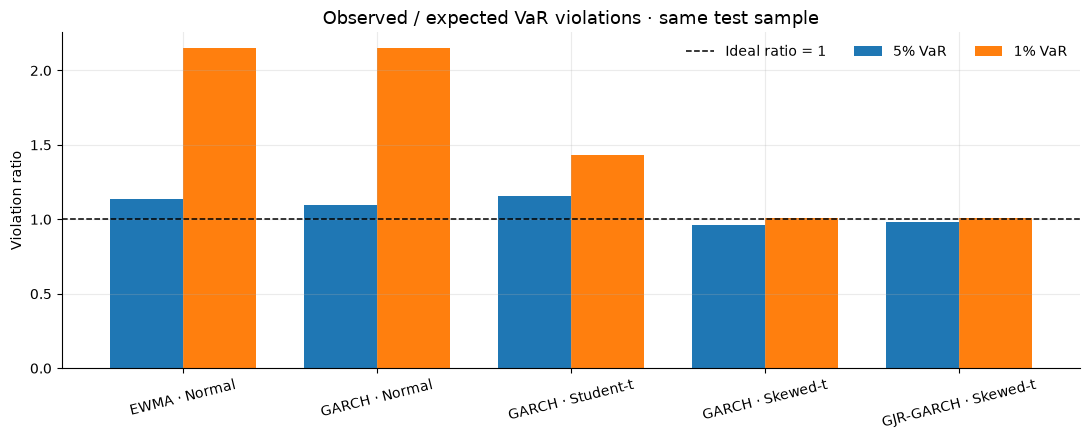

In [8]:
vr_comparison = comparison["violation_ratio"].unstack("alpha")
vr_comparison = vr_comparison.rename(columns={0.05: "5% VaR", 0.01: "1% VaR"})

ax = vr_comparison.plot.bar(width=0.75, figsize=(11, 4.5), rot=14)
ax.axhline(1, linewidth=1.1, color="black", linestyle="--", label="Ideal ratio = 1")
ax.set(title="Observed / expected VaR violations · same test sample",
       ylabel="Violation ratio", xlabel="")
ax.legend(frameon=False, ncol=3)
plt.tight_layout()
plt.show()

## 5. Inspect the 99% VaR forecasts

A close violation ratio alone does not tell us how the VaR thresholds evolve. This plot contrasts two representative specifications against realized one-day losses over the **last 300 forecast dates**.

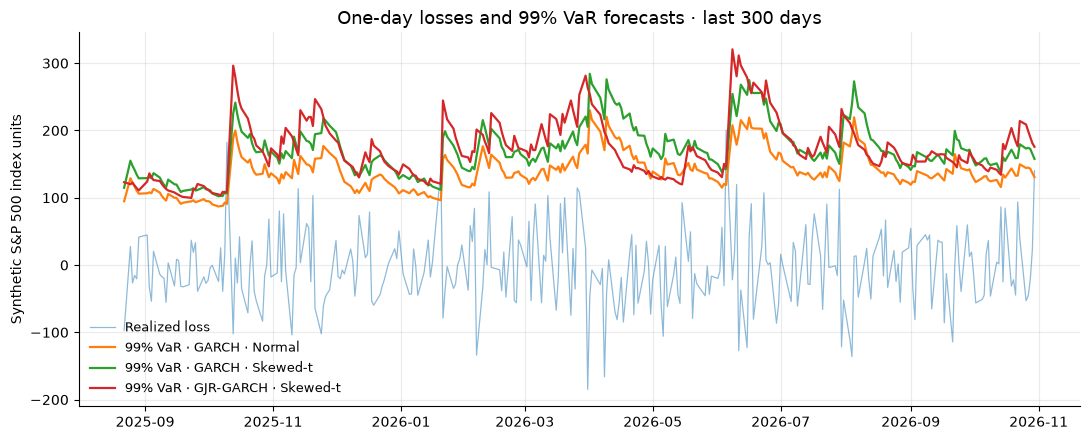

In [9]:
recent_dates = reference.index[-300:]
recent_losses = realized_losses.reindex(recent_dates)

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(recent_dates, recent_losses, alpha=0.5, linewidth=0.9,
        label="Realized loss")
for name in ("GARCH · Normal", "GARCH · Skewed-t", "GJR-GARCH · Skewed-t"):
    ax.plot(recent_dates, results[name]["VaR"].loc[recent_dates, 0.01],
            linewidth=1.6, label=f"99% VaR · {name}")
ax.set(title="One-day losses and 99% VaR forecasts · last 300 days",
       ylabel="Synthetic S&P 500 index units", xlabel="")
ax.legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

## 6. Brief conclusion

The original exploratory notebook showed that **Normal EWMA/GARCH tended to have too many 1% violations**, while models with **skewed Student-t innovations were much closer to the nominal tail probability**. The asymmetric GJR specification also improved the first-order independence statistic at 1% relative to the symmetric skewed-t GARCH in that run.

The following cell summarizes **your current rerun**, since downloaded adjusted prices and the estimation period may change. We should not select a “best” model based only on the violation ratio or the largest p-value; more discriminating forecast comparisons would use, for example, a quantile score.

In [10]:
tail_1pct = comparison.xs(0.01, level="alpha")
distance = (tail_1pct["violation_ratio"] - 1).abs()
nearest = distance.index[np.isclose(distance, distance.min())].tolist()
not_rejected = tail_1pct[["p_UC", "p_IND", "p_CC"]].ge(SIGNIFICANCE).all(axis=1)

print("1% VaR: closest violation ratio to 1:", ", ".join(nearest))
print("Models not rejected by any of the three 1% VaR tests at 5% significance:")
print("  " + (", ".join(not_rejected.index[not_rejected]) or "None"))
print("Interpretation: non-rejection is not proof of model adequacy.")

1% VaR: closest violation ratio to 1: GARCH · Skewed-t, GJR-GARCH · Skewed-t
Models not rejected by any of the three 1% VaR tests at 5% significance:
  GARCH · Skewed-t, GJR-GARCH · Skewed-t
Interpretation: non-rejection is not proof of model adequacy.
